# Bank Term Deposit Subscription Prediction - Logistic Regression Case Study

## Problem Statement

**Objective:**  
Build a machine learning classification model to predict whether a client of a Portuguese banking institution will subscribe to a **term deposit** following a direct marketing campaign conducted through phone calls.

The target variable, **`y`**, indicates whether the client subscribed to the term deposit (`yes`/`no`). The project will involve **exploratory data analysis, data preprocessing, feature engineering, model training, and evaluation** using suitable classification algorithms.

**Business Goal:**  
Develop a predictive model that can help the bank identify customers who are more likely to subscribe to a term deposit, enabling the marketing team to **target potential customers more effectively, reduce unnecessary calls, and improve overall campaign efficiency**.

In [51]:
#Import libraries
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [52]:
#Load the Dataset
filepath = r"C:\Users\jeevi\Downloads\data_files\bank-additional-full.csv"
df = pd.read_csv(filepath, sep=';')
df.head(5)

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


### Exploratory Data Analysis (EDA)

In [53]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  object 
 2   marital         41188 non-null  object 
 3   education       41188 non-null  object 
 4   default         41188 non-null  object 
 5   housing         41188 non-null  object 
 6   loan            41188 non-null  object 
 7   contact         41188 non-null  object 
 8   month           41188 non-null  object 
 9   day_of_week     41188 non-null  object 
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  object 
 15  emp.var.rate    41188 non-null  float64
 16  cons.price.idx  41188 non-null  float64
 17  cons.conf.idx   41188 non-null 

In [54]:
# Statistical summary of numeric columns
df.describe()

,age,duration,campaign,pdays,previous,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed
count,41188.00000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000
mean,40.02406,258.285010,2.567593,962.475454,0.172963,0.081886,93.575664,-40.502600,3.621291,5167.035911
std,10.42125,259.279249,2.770014,186.910907,0.494901,1.570960,0.578840,4.628198,1.734447,72.251528
min,17.00000,0.000000,1.000000,0.000000,0.000000,-3.400000,92.201000,-50.800000,0.634000,4963.600000
25%,32.00000,102.000000,1.000000,999.000000,0.000000,-1.800000,93.075000,-42.700000,1.344000,5099.100000
50%,38.00000,180.000000,2.000000,999.000000,0.000000,1.100000,93.749000,-41.800000,4.857000,5191.000000
75%,47.00000,319.000000,3.000000,999.000000,0.000000,1.400000,93.994000,-36.400000,4.961000,5228.100000
max,98.00000,4918.000000,56.000000,999.000000,7.000000,1.400000,94.767000,-26.900000,5.045000,5228.100000


### Observations:

- All 10 numerical column have 41188 observations indicating no missing values.
- The age ranges from 17 to 98 suggesting the dataset include wide range of customer age groups.
- Maximum duration is 4918 which indicate potential right skewness and unsually long calls.
- Customers received an average of 2.57 contacts during the current campaign, but the maximum is 56, suggesting extreme values that should be investigated.
- The median and 75th percentile are 999, indicating that many customers were likely not contacted in a previous campaign.(Here, 999 is a special code, not a literal number of days)

In [55]:
#To detect the null values
df.isnull().sum().sum()

np.int64(0)

In [56]:
# To view columns:
df.columns

Index(['age', 'job', 'marital', 'education', 'default', 'housing', 'loan',
       'contact', 'month', 'day_of_week', 'duration', 'campaign', 'pdays',
       'previous', 'poutcome', 'emp.var.rate', 'cons.price.idx',
       'cons.conf.idx', 'euribor3m', 'nr.employed', 'y'],
      dtype='object')

In [57]:
# Handle missing values by imputing categorical columns with their mode
# and numerical columns with their mean.
for i in df.columns:
    if(df[i].dtypes == "object"):
        df[i] =  df[i].fillna(df[i].mode()[0])
    else:
        df[i] = df[i].fillna(df[i].mean())
    

In [58]:
# To Find and Handle the duplicates
df.duplicated().sum()

np.int64(12)

In [59]:
df.drop_duplicates(inplace=True)

In [60]:
df.duplicated().sum()

np.int64(0)

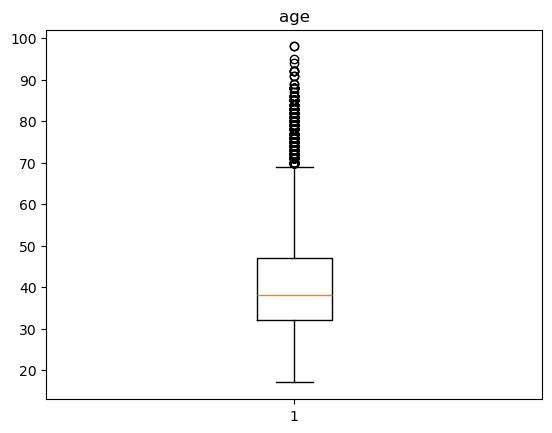

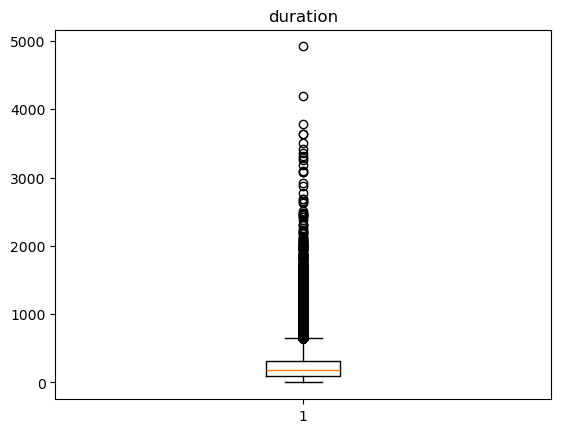

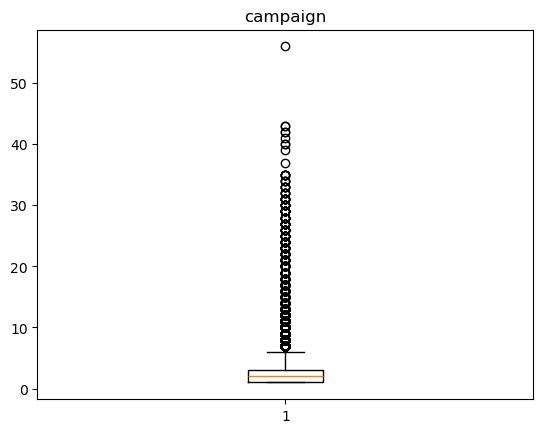

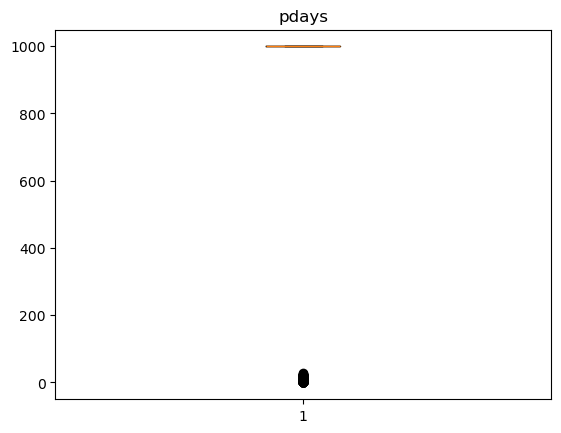

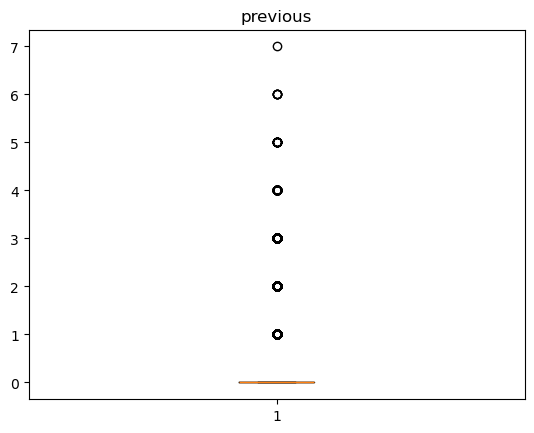

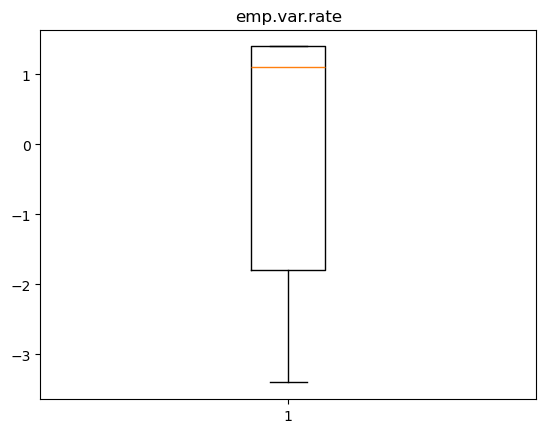

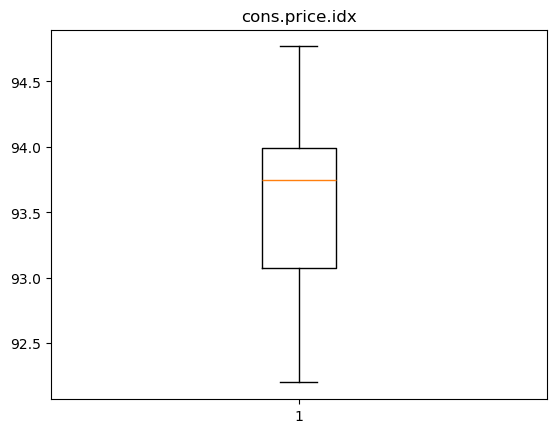

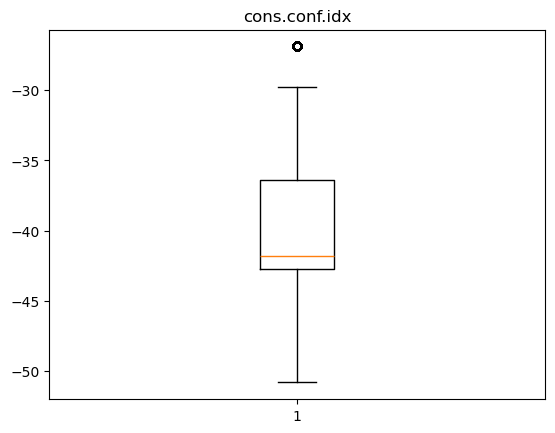

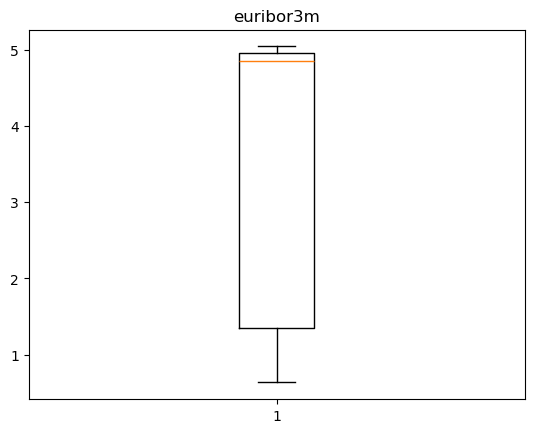

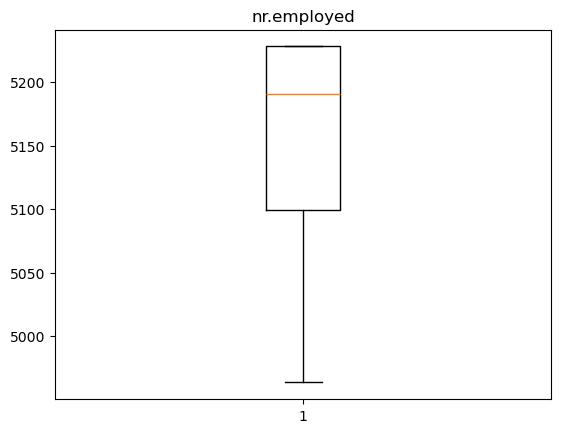

In [61]:
#Check for outliers
for i in df.columns:
    if(df[i].dtype != "object"):
        plt.boxplot(df[i])
        plt.title(i)
        plt.show()
        

### Observations:
- *duration*: The box plot reveals outliers with unusually long call durations compared to the majority of calls. These observations may represent genuine customer interactions rather than errors.
- *campaign*: Several outliers indicate that some customers were contacted substantially more times during the current marketing campaign than most customers.
- *cons.conf.idx*: Outliers are present in the consumer confidence index, indicating some observations with unusually high or low values relative to the central distribution.
- Outlier treatment: The identified outliers should be investigated before removal or transformation, as they may contain meaningful information about customer behavior and economic conditions.

In [62]:
outliers = ["duration", "campaign", "cons.conf.idx"]

In [63]:
# Remove outliers from the specified columns using the IQR (Interquartile Range) method.
for i in outliers:
    Q1 = df[i].quantile(0.25)
    Q3 = df[i].quantile(0.75)
    IQR = Q3-Q1
    UB = Q3 + 1.5*IQR
    LB = Q1 - 1.5*IQR
    df = df[(df[i] >= LB) & (df[i] <= UB)]

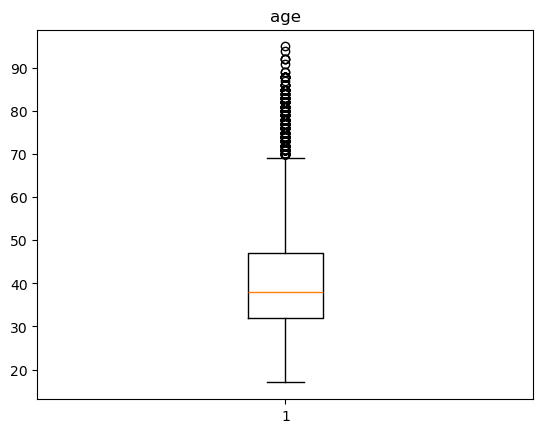

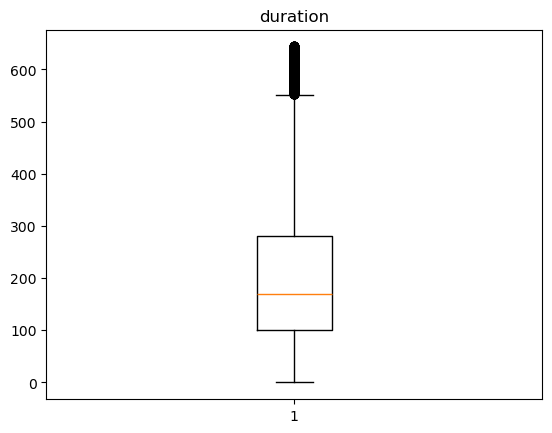

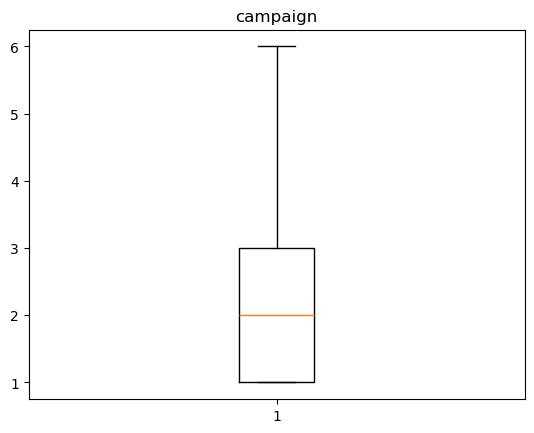

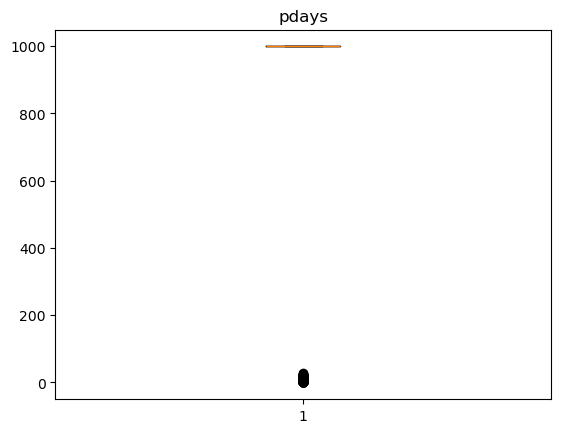

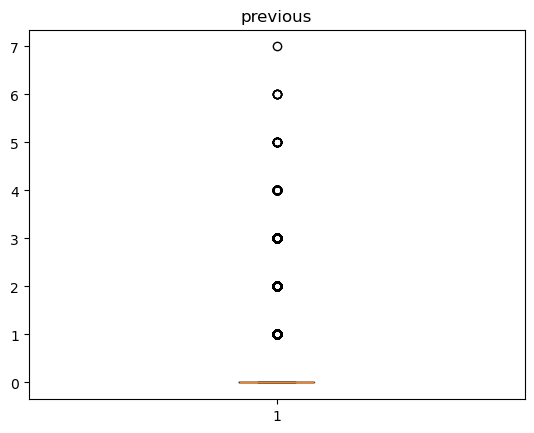

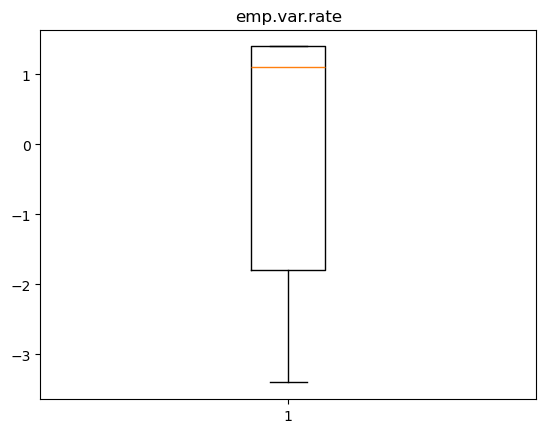

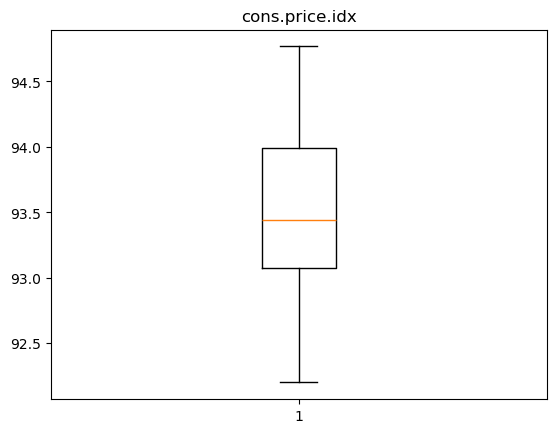

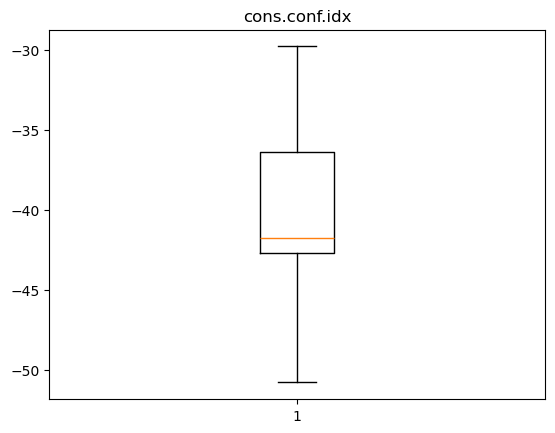

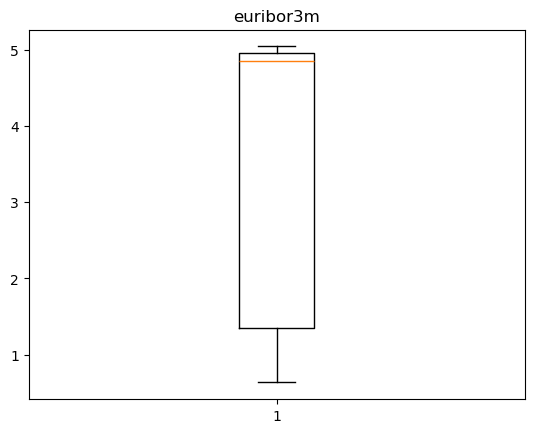

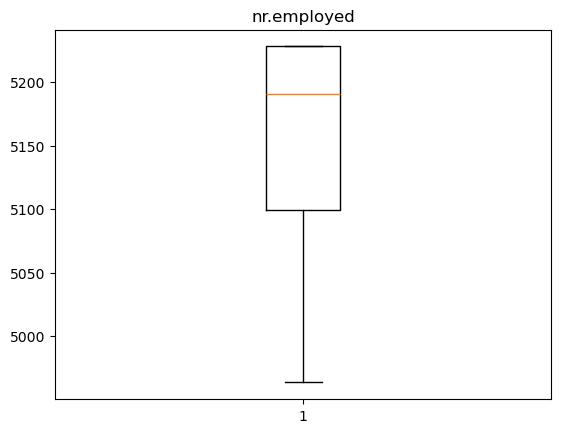

In [64]:
# Visualize the distribution of numerical features using box plots
# to identify potential outliers in each numerical column.
for i in df.columns:
    if (df[i].dtype != "object"):
        plt.boxplot(df[i])
        plt.title(i)
        plt.show()

In [65]:
#Label Encoding
#To find categorical column
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 35540 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             35540 non-null  int64  
 1   job             35540 non-null  object 
 2   marital         35540 non-null  object 
 3   education       35540 non-null  object 
 4   default         35540 non-null  object 
 5   housing         35540 non-null  object 
 6   loan            35540 non-null  object 
 7   contact         35540 non-null  object 
 8   month           35540 non-null  object 
 9   day_of_week     35540 non-null  object 
 10  duration        35540 non-null  int64  
 11  campaign        35540 non-null  int64  
 12  pdays           35540 non-null  int64  
 13  previous        35540 non-null  int64  
 14  poutcome        35540 non-null  object 
 15  emp.var.rate    35540 non-null  float64
 16  cons.price.idx  35540 non-null  float64
 17  cons.conf.idx   35540 non-null  floa

In [66]:
from sklearn.preprocessing import LabelEncoder

In [67]:
# Encode categorical features into numerical labels using LabelEncoder
# to convert text-based values into integers for machine learning.
for i in df.columns:
    if(df[i].dtypes == "object"):
        le = LabelEncoder()
        df[i] = le.fit_transform(df[i])

In [68]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 35540 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             35540 non-null  int64  
 1   job             35540 non-null  int64  
 2   marital         35540 non-null  int64  
 3   education       35540 non-null  int64  
 4   default         35540 non-null  int64  
 5   housing         35540 non-null  int64  
 6   loan            35540 non-null  int64  
 7   contact         35540 non-null  int64  
 8   month           35540 non-null  int64  
 9   day_of_week     35540 non-null  int64  
 10  duration        35540 non-null  int64  
 11  campaign        35540 non-null  int64  
 12  pdays           35540 non-null  int64  
 13  previous        35540 non-null  int64  
 14  poutcome        35540 non-null  int64  
 15  emp.var.rate    35540 non-null  float64
 16  cons.price.idx  35540 non-null  float64
 17  cons.conf.idx   35540 non-null  floa

### Model Building

In [84]:
#Steps to be performed:

#1. Separate the dataset into independent features (X) and the target variable (y).

#2. Split the dataset into training and testing sets.

#3. Train the machine learning model using the training data.

#4. Generate predictions using the test data.

#5. Evaluate the model's performance using appropriate evaluation metrics.

In [70]:
#Split the Dataset into x and y:
x = df.drop(columns="y")

In [71]:
y = df["y"]

In [72]:
# Train-Test Split
from sklearn.model_selection import train_test_split

In [73]:
X_train, X_test, y_train, y_test = train_test_split(x,y, test_size=0.2, random_state=42)

In [74]:
X_train.shape

(28432, 20)

In [75]:
X_test.shape

(7108, 20)

In [76]:
# Train the model
from sklearn.linear_model import LogisticRegression

In [77]:
model = LogisticRegression()

In [78]:
model.fit(X_train, y_train)

C:\Users\jeevi\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:473: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


In [79]:
# Test the Model
y_pred = model.predict(X_test)

In [80]:
#Evaluate the model
from sklearn.metrics import *

In [81]:
accuracy_score(y_test, y_pred)*100

93.44400675295442

### Observation:
The model achieved an accuracy of 93.44%, indicating that it correctly classified approximately 93% of the observations in the test dataset. However, accuracy alone may not fully reflect model performance because the target classes are imbalanced.

In [82]:
# Confusion Matrix
confusion_matrix(y_test, y_pred)

array([[6413,  106],
       [ 360,  229]])

### Observation:
- True Negatives (6,413): Correctly predicted customers who did not subscribe to a term deposit.
- False Positives (106): Customers incorrectly predicted to subscribe but who did not.
- False Negatives (360): Customers who subscribed but were incorrectly predicted not to subscribe.
- True Positives (229): Correctly predicted customers who subscribed to a term deposit.

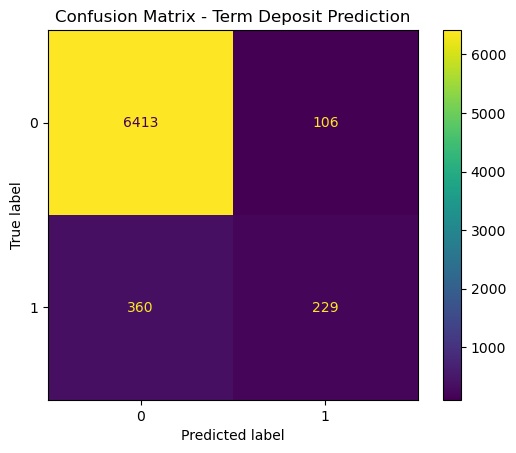

In [85]:
#visualization
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Visualize the confusion matrix to assess classification performance
ConfusionMatrixDisplay.from_predictions(y_test, y_pred)
plt.title("Confusion Matrix - Term Deposit Prediction")
plt.show()

### Observation:
The model correctly classified most non-subscribers but missed a considerable number of actual subscribers.

In [83]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.95      0.98      0.96      6519
           1       0.68      0.39      0.50       589

    accuracy                           0.93      7108
   macro avg       0.82      0.69      0.73      7108
weighted avg       0.93      0.93      0.93      7108



### Observation:
- *Class 0 (Non-subscribers)*: Achieved a precision of 0.95, recall of 0.98, and F1-score of 0.96, indicating strong performance in identifying customers who did not subscribe.

- *Class 1 (Subscribers)*: Achieved a precision of 0.68, recall of 0.39, and F1-score of 0.50. Although the model's predictions for subscribers are reasonably precise, it identifies only 39% of actual subscribers.

- *Macro Average*: The F1-score of **0.73** reflects the average performance across both classes, giving equal weight to each class.

- *Weighted Average*: The F1-score of **0.93** reflects the overall performance weighted by the number of observations in each class. The larger non-subscriber class has a greater influence on this score.

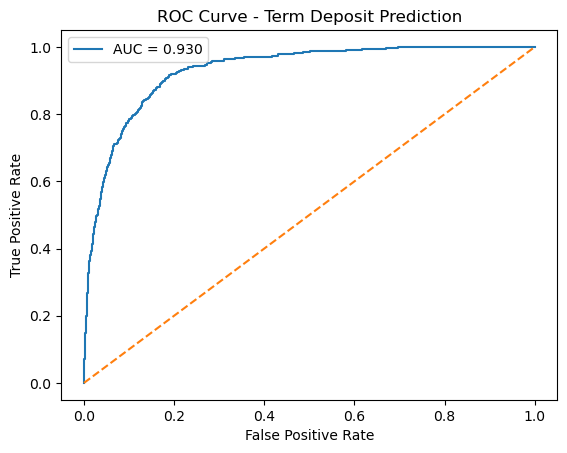

ROC-AUC Score: 0.9301831840114217


In [87]:
# Calculate predicted probabilities for the positive class (subscribed)
y_prob = model.predict_proba(X_test)[:, 1]

# Calculate the False Positive Rate (FPR), True Positive Rate (TPR),
# and threshold values for different classification thresholds
fpr, tpr, thresholds = roc_curve(y_test, y_prob)

# Calculate the Area Under the ROC Curve (ROC-AUC) score
auc_score = roc_auc_score(y_test, y_prob)

# Plot the ROC curve to evaluate the model's ability to distinguish between classes
plt.plot(fpr, tpr, label=f"AUC = {auc_score:.3f}")
plt.plot([0, 1], [0, 1], linestyle="--")  # Reference line for random classification
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Term Deposit Prediction")
plt.legend()
plt.show()

# Display the ROC-AUC score
print("ROC-AUC Score:", auc_score)

### Observation:
The model achieved a ROC-AUC score of 0.9302, indicating a strong ability to distinguish between customers who subscribed to a term deposit and those who did not. This suggests that the model can effectively rank subscribers above non-subscribers based on their predicted probabilities. However, the ROC-AUC score does not indicate how many actual subscribers are correctly identified at the current classification threshold.

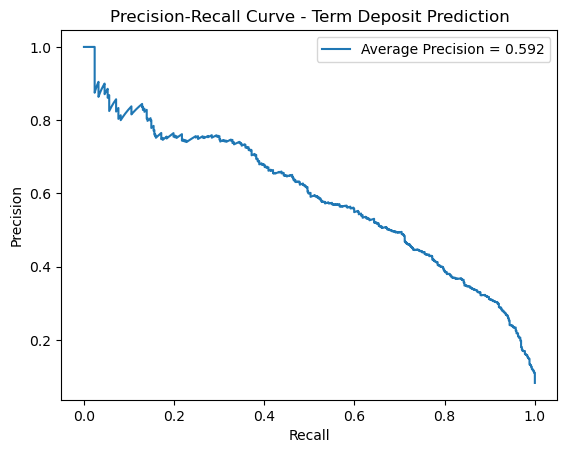

Average Precision Score: 0.5918


In [88]:
from sklearn.metrics import precision_recall_curve, average_precision_score
import matplotlib.pyplot as plt

# Calculate precision and recall at different classification thresholds
precision, recall, thresholds = precision_recall_curve(y_test, y_prob)

# Calculate the average precision score
ap_score = average_precision_score(y_test, y_prob)

# Plot the precision-recall curve
plt.plot(recall, precision, label=f"Average Precision = {ap_score:.3f}")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve - Term Deposit Prediction")
plt.legend()
plt.show()

# Display the average precision score
print(f"Average Precision Score: {ap_score:.4f}")

### Observation:
The model achieved an Average Precision (AP) score of 0.5918, indicating moderate precision-recall performance in identifying customers who subscribed to a term deposit. Although the model achieved a high ROC-AUC score of 0.9302, the Average Precision score suggests that identifying subscribers while maintaining high precision and recall remains challenging. Further improvements could include evaluating different classification thresholds and comparing alternative classification models.

### Conclusion:

The objective of this project was to predict whether a customer would subscribe to a term deposit based on marketing campaign data. The model achieved 93.44% accuracy, a ROC-AUC score of 0.9302, and an Average Precision score of 0.5918, indicating that it can distinguish between potential subscribers and non-subscribers reasonably well.

However, the model identified only 39% of actual subscribers at the current classification threshold, meaning that 360 out of 589 subscribers were incorrectly classified as non-subscribers. Therefore, despite its high overall accuracy, the model may miss many potential customers if used with the current threshold.

From a business perspective, the model shows potential for supporting targeted marketing campaigns, but further evaluation is needed before deployment. Adjusting the classification threshold and comparing alternative models could help the bank identify more potential subscribers while balancing unnecessary marketing contacts and campaign costs.